# Assignment 7: Image Sharpening

**Objective:** Sharpen a grayscale image with several techniques:
1. Laplacian sharpening
2. Gradient-based sharpening using Sobel and Canny edges
3. Unsharp masking

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Laplacian sharpening
`sharpened = image - Laplacian(image)`

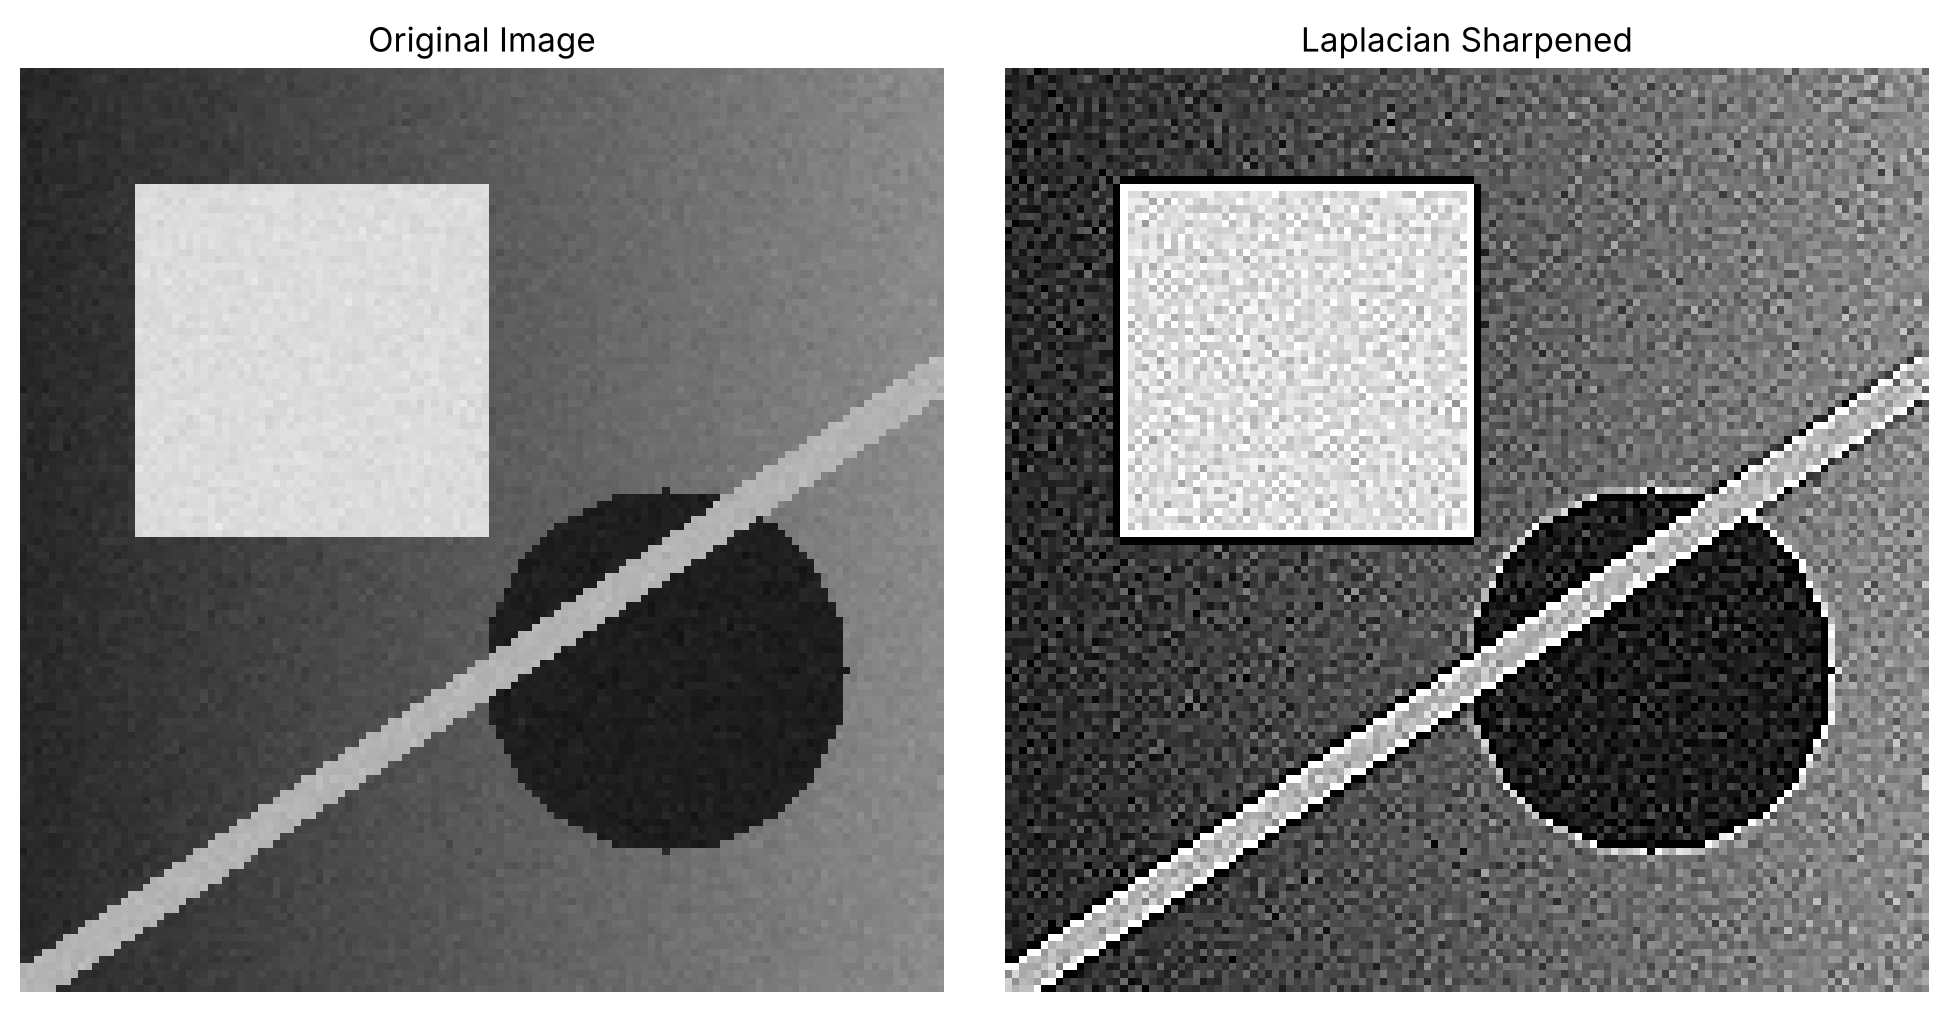

In [2]:
grayscale_image = create_demo_image()

laplacian = cv2.Laplacian(grayscale_image, cv2.CV_64F)
laplacian_sharpened = np.clip(grayscale_image - laplacian, 0, 255).astype(np.uint8)

show_images([grayscale_image, laplacian_sharpened], ["Original Image", "Laplacian Sharpened"], figsize=(10, 5))

## Part B: Sobel and Canny edge sharpening
The edge map (scaled by 0.5) is added back to the original image.

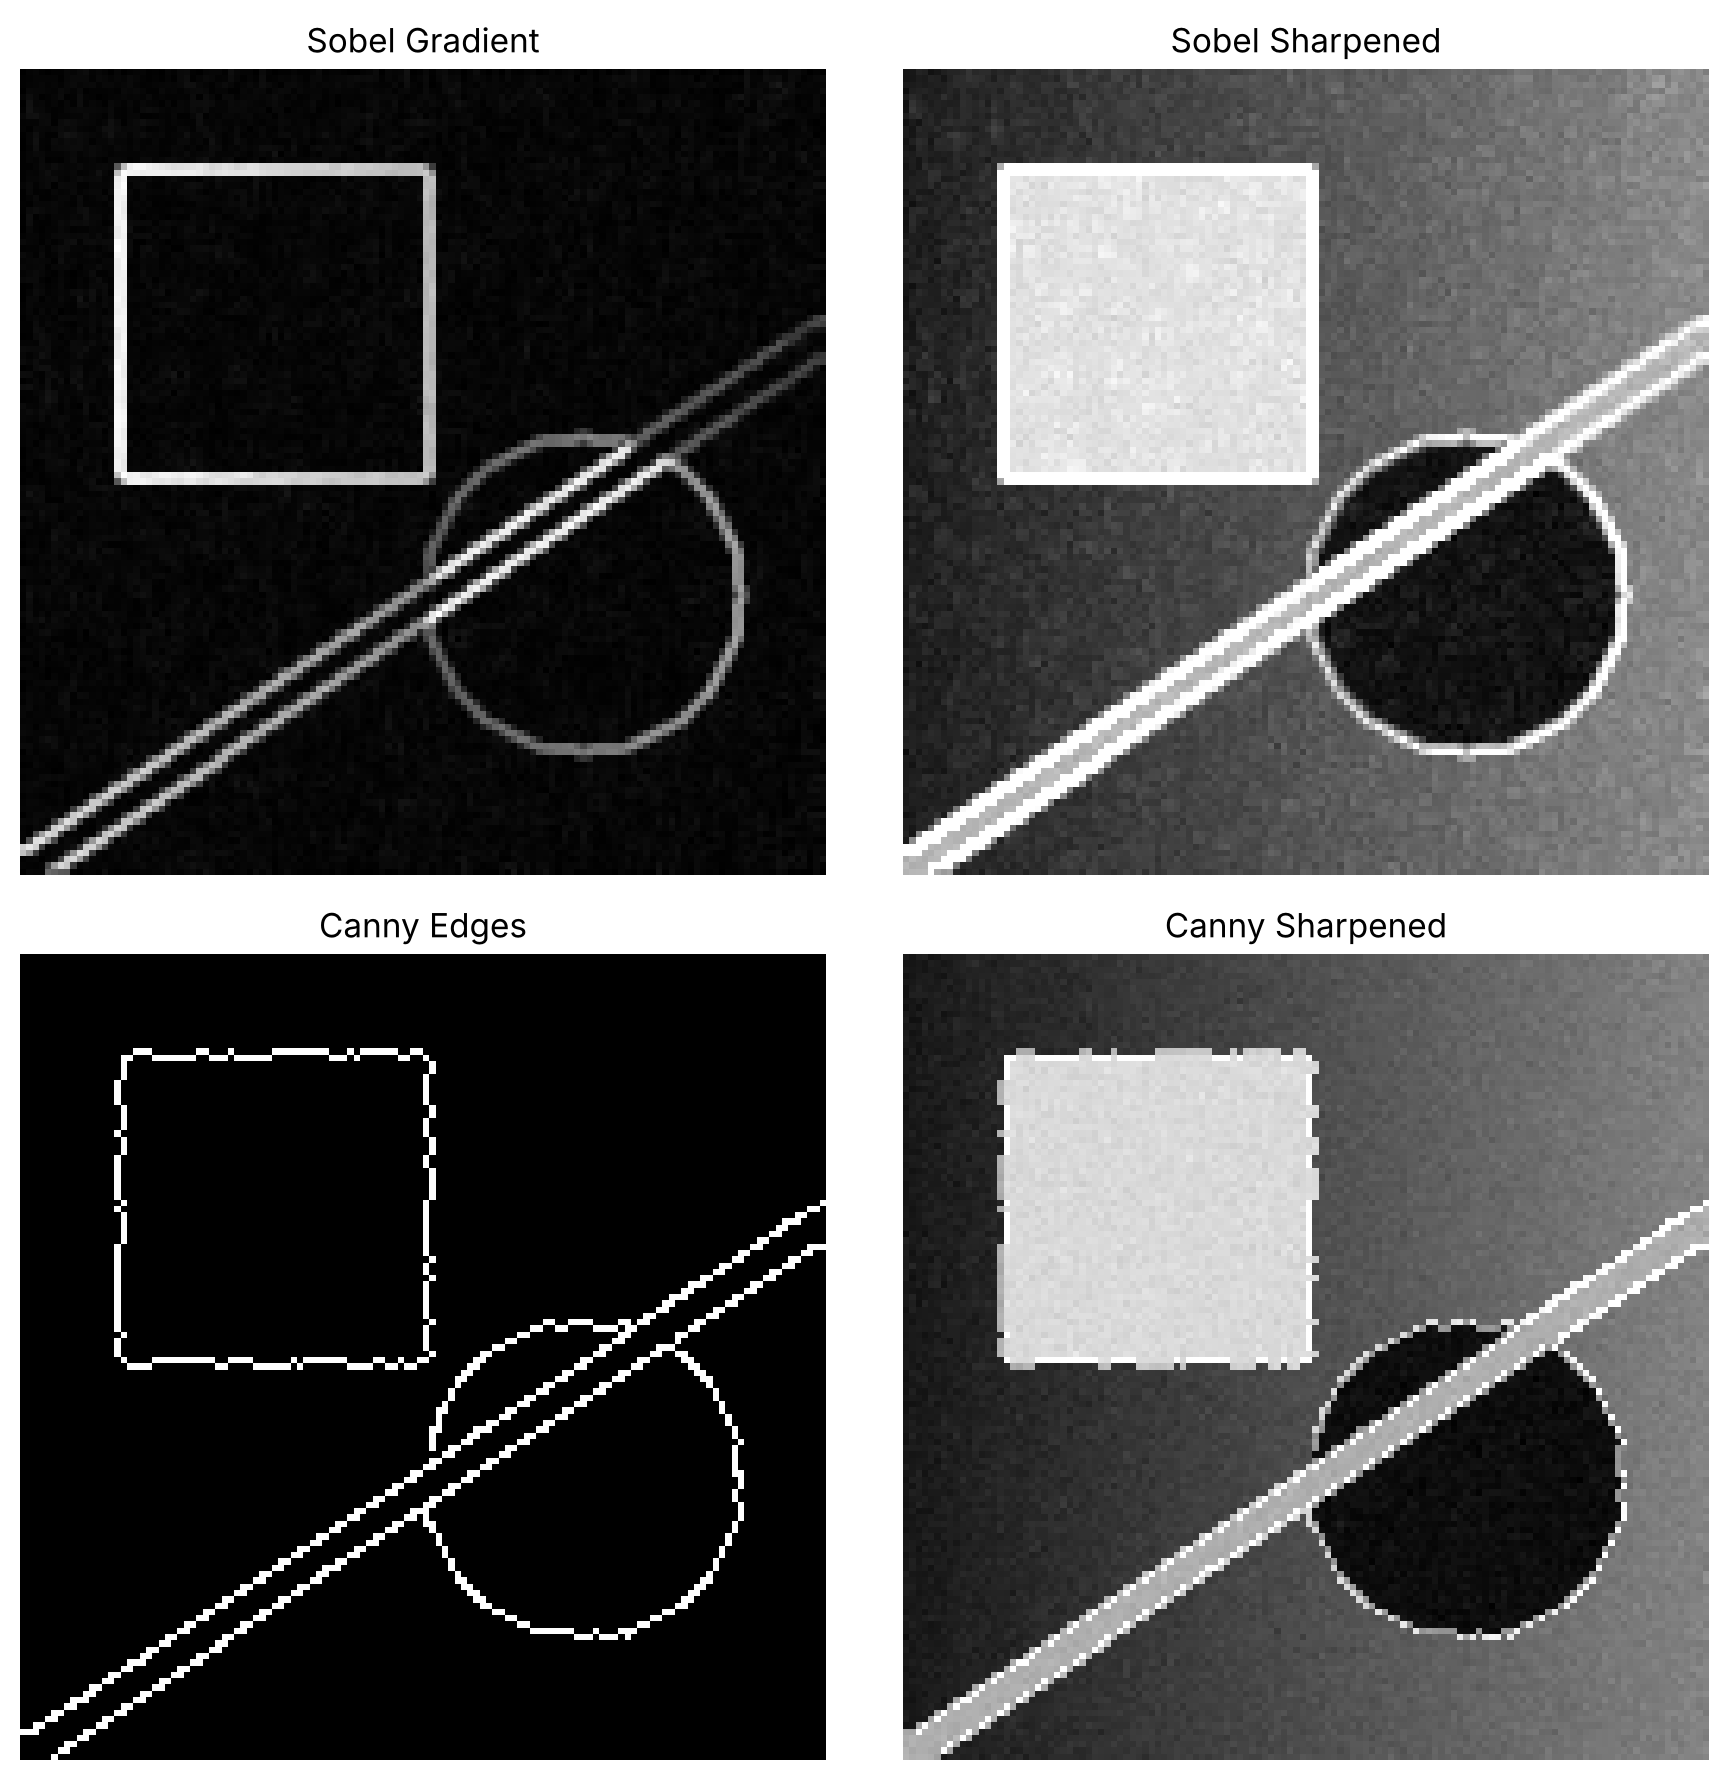

In [3]:
grayscale_image = create_demo_image()

sobel_x = cv2.Sobel(grayscale_image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(grayscale_image, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
sobel_sharpened = np.clip(grayscale_image + 0.5 * sobel_magnitude, 0, 255).astype(np.uint8)

canny_edges = cv2.Canny(grayscale_image, 100, 200)
canny_sharpened = np.clip(grayscale_image + 0.5 * canny_edges, 0, 255).astype(np.uint8)

# Sobel magnitude can exceed 255, so let matplotlib scale it for display
plt.figure(figsize=(9, 9))
panels = [(sobel_magnitude, "Sobel Gradient"), (sobel_sharpened, "Sobel Sharpened"),
          (canny_edges, "Canny Edges"), (canny_sharpened, "Canny Sharpened")]
for index, (panel, title) in enumerate(panels, start=1):
    plt.subplot(2, 2, index)
    plt.imshow(panel, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Part C: Unsharp masking
`mask = image - blurred`, `sharpened = image + k * mask` with `k = 1`, using a 5x5 Gaussian blur (sigma = 3).

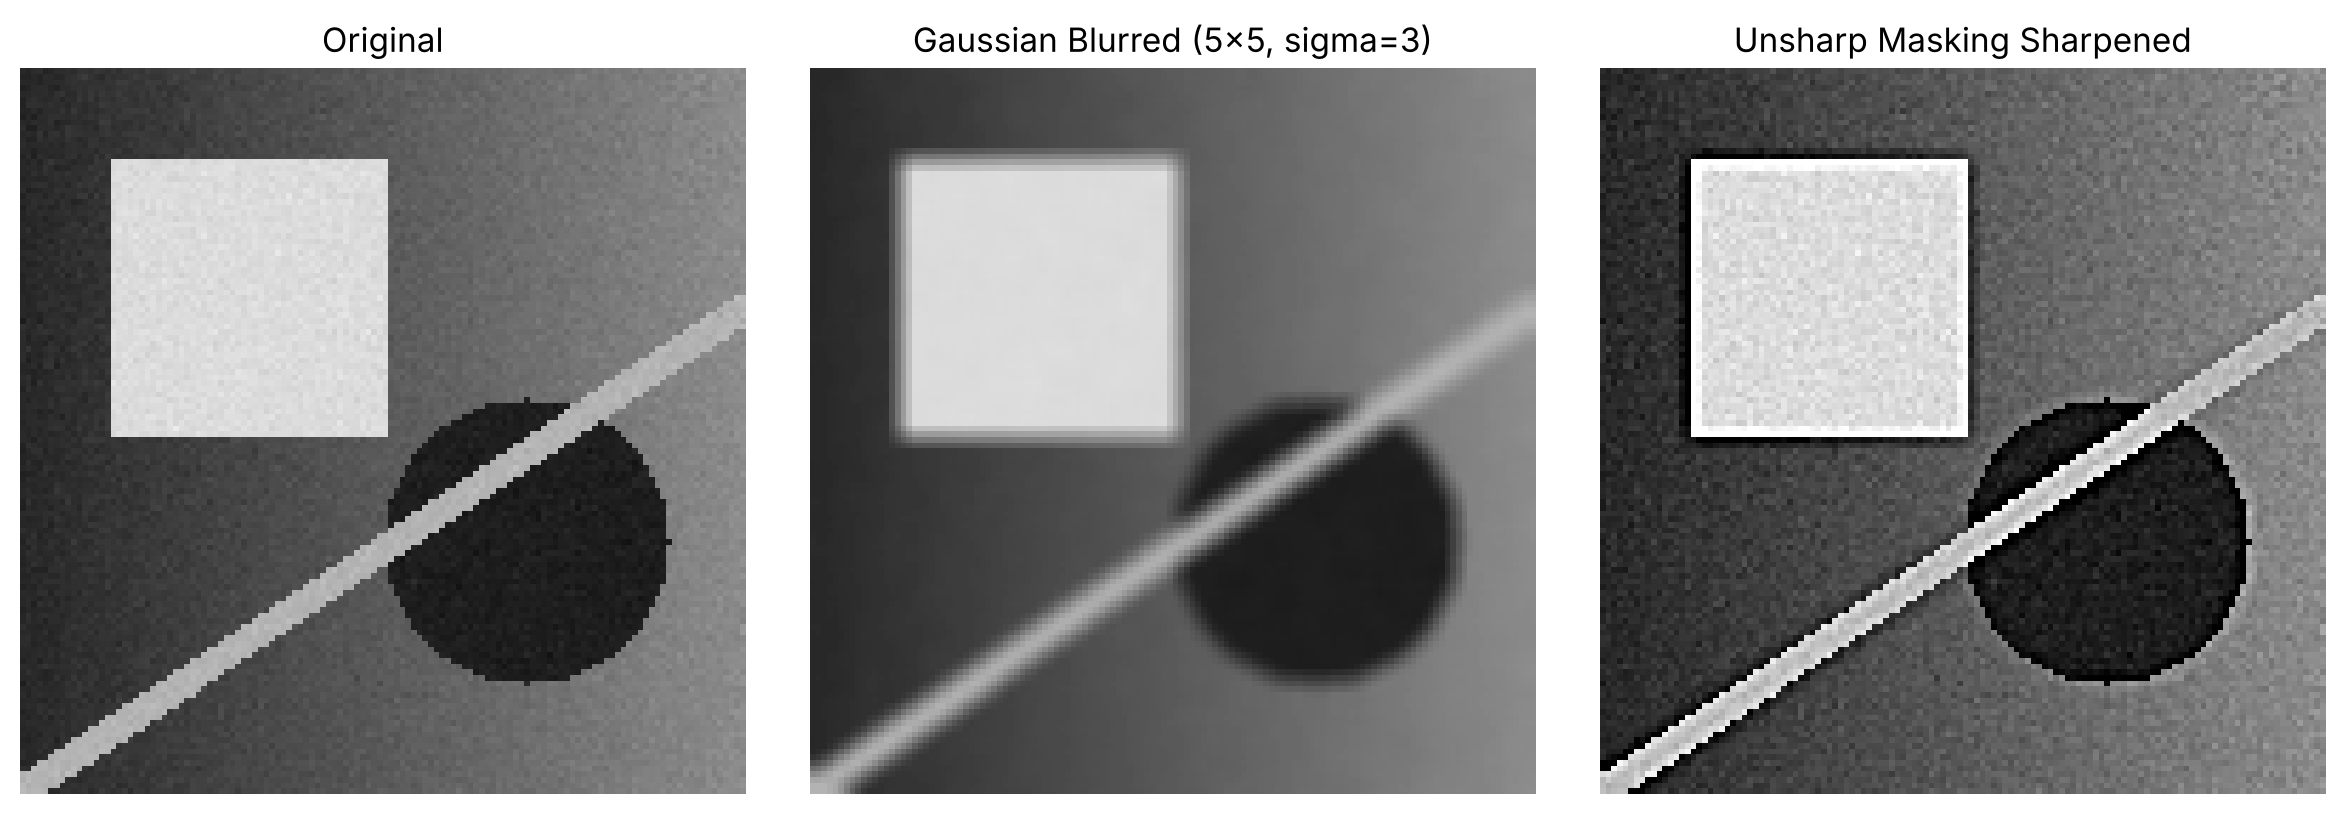

In [4]:
grayscale_image = create_demo_image()

blurred_image = cv2.GaussianBlur(grayscale_image, (5, 5), 3)
detail_mask = grayscale_image.astype(np.float32) - blurred_image.astype(np.float32)
unsharp_sharpened = np.clip(grayscale_image + 1.0 * detail_mask, 0, 255).astype(np.uint8)

show_images([grayscale_image, blurred_image, unsharp_sharpened],
            ["Original", "Gaussian Blurred (5x5, sigma=3)", "Unsharp Masking Sharpened"], figsize=(12, 4))